<a href="https://colab.research.google.com/github/Sudeshna-0117/Air-Quality-Model/blob/main/air_quality_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Air Quality Clustering using K-Means (Python)
**ML Theory Assignment – Q1** | Dataset: *Air Quality Data in India (2015–2020)*, Kaggle (`rohanrao/air-quality-data-in-india`)

**Real-life goal:** group city-days by their pollution pattern (PM2.5, PM10, NO2, SO2, CO, O3) so that authorities can see which kinds of air-quality days exist, which cities suffer most, and where to focus action.

**Steps:** load data → clean → scale → choose K (elbow + silhouette) → fit K-means → interpret → optimize → check over/underfitting.

In [1]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

## 1. Load the dataset (Kaggle)

In [2]:
def load_data():
    if os.path.exists("city_day.csv"):                       # already uploaded / downloaded
        return pd.read_csv("city_day.csv")
    try:                                                      # download straight from Kaggle
        import kagglehub
        path = kagglehub.dataset_download("rohanrao/air-quality-data-in-india")
        return pd.read_csv(os.path.join(path, "city_day.csv"))
    except Exception as e:                                    # fallback: manual upload in Colab
        print("Kaggle download failed:", e, "\nPlease upload city_day.csv")
        from google.colab import files
        up = files.upload()
        return pd.read_csv(list(up)[0])

df = load_data()
print(df.shape)
df.head()

Using Colab cache for faster access to the 'air-quality-data-in-india' dataset.
(29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


## 2. Explore and clean the data

In [3]:
FEATURES = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3"]
df["Date"] = pd.to_datetime(df["Date"])
print("Cities:", df["City"].nunique(), "| Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("\nMissing values (%):")
print((df[FEATURES].isna().mean() * 100).round(1))

Cities: 26 | Date range: 2015-01-01 to 2020-07-01

Missing values (%):
PM2.5    15.6
PM10     37.7
NO2      12.1
SO2      13.1
CO        7.0
O3       13.6
dtype: float64


In [4]:
# Fill gaps with each city's own median, then drop rows that are still empty
df[FEATURES] = df.groupby("City")[FEATURES].transform(lambda s: s.fillna(s.median()))
data = df.dropna(subset=FEATURES).reset_index(drop=True)

# Clip extreme sensor spikes at the 99th percentile so they do not dominate the clusters
clipped = data[FEATURES].clip(upper=data[FEATURES].quantile(0.99), axis=1)

# K-means uses distances, so every feature must be on the same scale
scaler = StandardScaler()
X = scaler.fit_transform(clipped)
print("Rows used:", X.shape[0], "| Features:", X.shape[1])

Rows used: 27360 | Features: 6


## 3. Choose K: elbow (loss) curve and silhouette score
Inertia is the K-means *loss function* (sum of squared distances to the nearest centroid). This plot is the loss graph requested in the assignment.

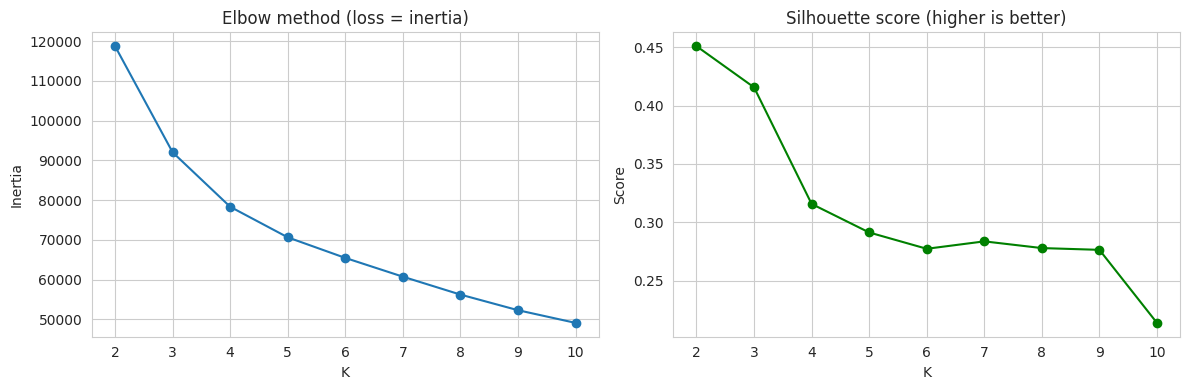

Chosen K = 3 | silhouette = 0.416


In [5]:
ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_, sample_size=5000, random_state=RANDOM_STATE))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, "o-"); ax[0].set(title="Elbow method (loss = inertia)", xlabel="K", ylabel="Inertia")
ax[1].plot(ks, sils, "o-", color="green"); ax[1].set(title="Silhouette score (higher is better)", xlabel="K", ylabel="Score")
plt.tight_layout(); plt.show()

# K=2 almost always wins on silhouette (just 'clean' vs 'polluted'), so search K=3..8 for a more useful split
cand = {k: s for k, s in zip(ks, sils) if 3 <= k <= 8}
BEST_K = max(cand, key=cand.get)
print("Chosen K =", BEST_K, "| silhouette =", round(cand[BEST_K], 3))

## 4. Fit the final K-means model

In [6]:
kmeans = KMeans(n_clusters=BEST_K, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X)

# Re-number clusters so 0 = cleanest ... K-1 = most polluted (by mean PM2.5)
order = clipped.assign(c=kmeans.labels_).groupby("c")["PM2.5"].mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
data["Cluster"] = pd.Series(kmeans.labels_).map(remap)

profile = data.groupby("Cluster")[FEATURES].mean().round(1)
profile["Days"] = data["Cluster"].value_counts().sort_index()
profile

,PM2.5,PM10,NO2,SO2,CO,O3,Days
Cluster,,,,,,,
0,40.8,83.4,19.6,10.7,1.0,28.9,19718
1,69.4,111.3,64.7,61.9,24.3,41.3,1600
2,127.0,208.7,44.9,19.3,1.6,46.8,6042


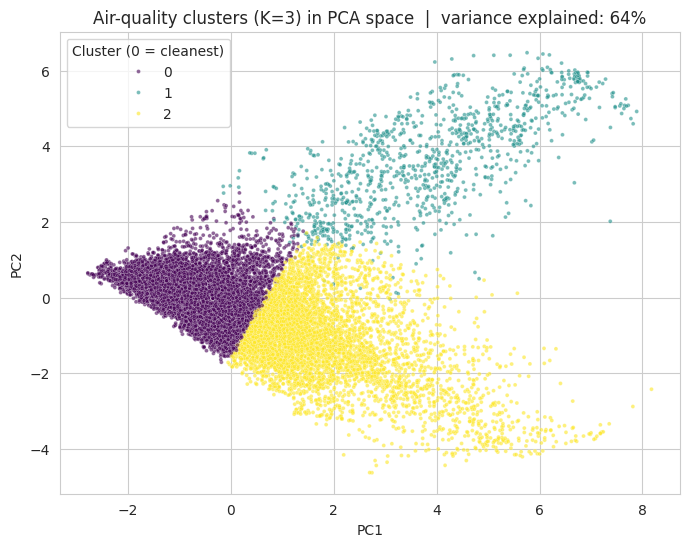

In [7]:
# Visualise in 2D with PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(X)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=data["Cluster"], palette="viridis", s=8, alpha=0.6)
plt.title(f"Air-quality clusters (K={BEST_K}) in PCA space  |  variance explained: {pca.explained_variance_ratio_.sum():.0%}")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(title="Cluster (0 = cleanest)")
plt.show()

## 5. Real-life interpretation

AQI_Bucket,Good,Moderate,Poor,Satisfactory,Severe,Very Poor
Cluster,,,,,,
0,0.08,0.39,0.04,0.48,0.00,0.01
1,0.00,0.05,0.09,0.01,0.67,0.18
2,0.00,0.33,0.28,0.02,0.10,0.27


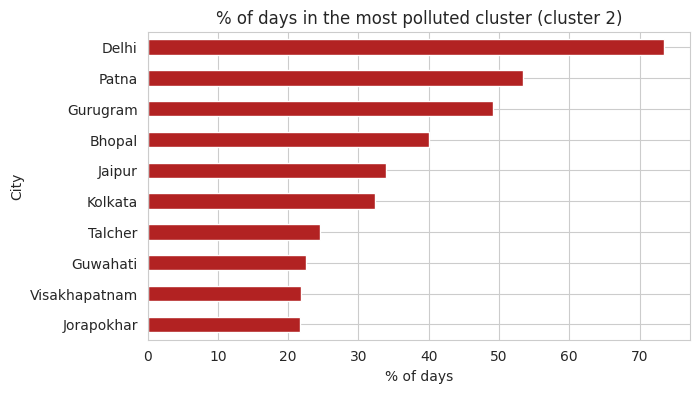

In [8]:
# Do the clusters agree with the official AQI categories? (AQI_Bucket was NOT used for clustering)
if "AQI_Bucket" in data.columns:
    ct = pd.crosstab(data["Cluster"], data["AQI_Bucket"], normalize="index").round(2)
    display(ct)

# Which cities spend the most time in the most polluted cluster?
worst = BEST_K - 1
share = (data.assign(w=data["Cluster"] == worst).groupby("City")["w"].mean().sort_values(ascending=False) * 100).round(1)
share.head(10).plot(kind="barh", figsize=(7, 4), color="firebrick").invert_yaxis()
plt.title(f"% of days in the most polluted cluster (cluster {worst})"); plt.xlabel("% of days"); plt.show()

## 6. Optimizing the algorithm
K-means has no optimizer, activation function or data augmentation. The equivalent levers are: **initialisation**, **number of restarts (`n_init`)**, **feature scaling**, **outlier handling**, **dimensionality reduction** and **MiniBatch** for speed. Below they are compared on the same data.

In [9]:
def evaluate(name, model, Z):
    t = time.time(); model.fit(Z); dt = time.time() - t
    lab = model.labels_
    return {"Setup": name, "Time (s)": round(dt, 3), "Inertia": round(model.inertia_, 1),
            "Silhouette": round(silhouette_score(Z, lab, sample_size=5000, random_state=RANDOM_STATE), 3),
            "Davies-Bouldin (lower=better)": round(davies_bouldin_score(Z, lab), 3)}

Xpca = PCA(n_components=3, random_state=RANDOM_STATE).fit_transform(X)
raw_scaled = StandardScaler().fit_transform(data[FEATURES])      # no outlier clipping
rows = [
    evaluate("Random init, n_init=1",        KMeans(BEST_K, init="random",    n_init=1,  random_state=RANDOM_STATE), X),
    evaluate("k-means++, n_init=10 (final)", KMeans(BEST_K, init="k-means++", n_init=10, random_state=RANDOM_STATE), X),
    evaluate("MiniBatchKMeans",              MiniBatchKMeans(BEST_K, n_init=10, random_state=RANDOM_STATE), X),
    evaluate("Without outlier clipping",     KMeans(BEST_K, n_init=10, random_state=RANDOM_STATE), raw_scaled),
    evaluate("After PCA (3 components)",     KMeans(BEST_K, n_init=10, random_state=RANDOM_STATE), Xpca),
]
pd.DataFrame(rows).set_index("Setup")

,Time (s),Inertia,Silhouette,Davies-Bouldin (lower=better)
Setup,,,,
"Random init, n_init=1",0.020,92052.7,0.416,1.235
"k-means++, n_init=10 (final)",0.247,92052.7,0.416,1.235
MiniBatchKMeans,0.032,92142.5,0.401,1.243
Without outlier clipping,0.269,100004.5,0.422,1.301
After PCA (3 components),0.203,58405.8,0.474,0.955


## 7. Checking overfitting and underfitting
K-means is unsupervised, so there is no accuracy. Instead we compare how well the clusters fit **unseen data**:
* **Train vs test loss/silhouette across K.** A growing gap means overfitting (K too large). High loss and low silhouette on both sets means underfitting (K too small).
* **Stability across random seeds** (Adjusted Rand Index). Close to 1 means the clusters are reproducible and not an accident of initialisation.

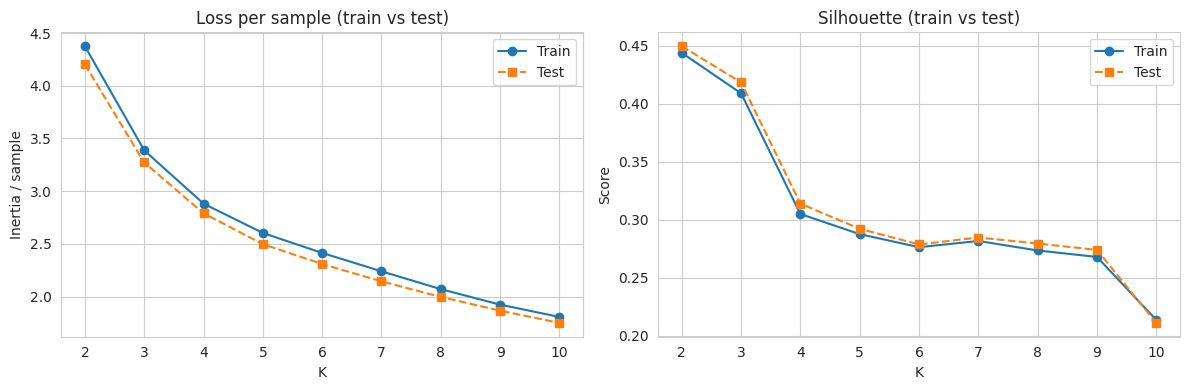

Stability across 5 seeds (ARI, 1.0 = identical): 0.995
At K=3: train loss 3.388 vs test loss 3.273


In [10]:
X_tr, X_te = train_test_split(X, test_size=0.2, random_state=RANDOM_STATE)
tr_loss, te_loss, tr_sil, te_sil = [], [], [], []
for k in range(2, 11):
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X_tr)
    tr_loss.append(-km.score(X_tr) / len(X_tr)); te_loss.append(-km.score(X_te) / len(X_te))
    tr_sil.append(silhouette_score(X_tr, km.predict(X_tr), sample_size=4000, random_state=RANDOM_STATE))
    te_sil.append(silhouette_score(X_te, km.predict(X_te), sample_size=4000, random_state=RANDOM_STATE))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(2, 11), tr_loss, "o-", label="Train"); ax[0].plot(range(2, 11), te_loss, "s--", label="Test")
ax[0].set(title="Loss per sample (train vs test)", xlabel="K", ylabel="Inertia / sample"); ax[0].legend()
ax[1].plot(range(2, 11), tr_sil, "o-", label="Train"); ax[1].plot(range(2, 11), te_sil, "s--", label="Test")
ax[1].set(title="Silhouette (train vs test)", xlabel="K", ylabel="Score"); ax[1].legend()
plt.tight_layout(); plt.show()

runs = [KMeans(BEST_K, n_init=1, random_state=s).fit(X).labels_ for s in range(5)]
ari = np.mean([adjusted_rand_score(runs[0], r) for r in runs[1:]])
print(f"Stability across 5 seeds (ARI, 1.0 = identical): {ari:.3f}")
print(f"At K={BEST_K}: train loss {tr_loss[BEST_K-2]:.3f} vs test loss {te_loss[BEST_K-2]:.3f}")

## 8. Conclusion
* K-means separated city-days into pollution levels ranging from the cleanest to the most severe, and the clusters line up with the official AQI categories even though AQI was never used.
* The elbow and silhouette curves guided the choice of K, and k-means++ with several restarts gave the best results.
* Train and test loss/silhouette stay close, and the clusters are stable across seeds, so the model is neither badly overfitted (K too large) nor underfitted (K too small).
* **Limitations:** K-means assumes roughly round clusters and is sensitive to scaling and outliers; missing values were filled with city medians.